In [1]:
!pip install pandas numpy scikit-learn matplotlib joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load Boston Housing Dataset

boston = fetch_openml(
    data_id=531,
    as_frame=True
)

# Convert dataset into DataFrame
df = boston.frame

print("Dataset loaded successfully!")

print(df.head())

Dataset loaded successfully!
      CRIM    ZN  INDUS CHAS    NOX     RM   AGE     DIS RAD    TAX  PTRATIO  \
0  0.00632  18.0   2.31    0  0.538  6.575  65.2  4.0900   1  296.0     15.3   
1  0.02731   0.0   7.07    0  0.469  6.421  78.9  4.9671   2  242.0     17.8   
2  0.02729   0.0   7.07    0  0.469  7.185  61.1  4.9671   2  242.0     17.8   
3  0.03237   0.0   2.18    0  0.458  6.998  45.8  6.0622   3  222.0     18.7   
4  0.06905   0.0   2.18    0  0.458  7.147  54.2  6.0622   3  222.0     18.7   

        B  LSTAT  MEDV  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4.03  34.7  
3  394.63   2.94  33.4  
4  396.90   5.33  36.2  


In [4]:
# Display dataset information

print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(506, 14)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   CRIM     506 non-null    float64 
 1   ZN       506 non-null    float64 
 2   INDUS    506 non-null    float64 
 3   CHAS     506 non-null    category
 4   NOX      506 non-null    float64 
 5   RM       506 non-null    float64 
 6   AGE      506 non-null    float64 
 7   DIS      506 non-null    float64 
 8   RAD      506 non-null    category
 9   TAX      506 non-null    float64 
 10  PTRATIO  506 non-null    float64 
 11  B        506 non-null    float64 
 12  LSTAT    506 non-null    float64 
 13  MEDV     506 non-null    float64 
dtypes: category(2), float64(12)
memory usage: 48.7 KB

Missing Values:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT  

In [5]:
# Separate features and target

X = df.drop(columns=['MEDV'])

y = pd.to_numeric(df['MEDV'])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (506, 13)
Target shape: (506,)


In [6]:
# Handle missing values

imputer = SimpleImputer(strategy='median')

X_imputed = imputer.fit_transform(X)

# Scale the features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print("Missing values handled successfully!")
print("Feature scaling completed!")

Missing values handled successfully!
Feature scaling completed!


In [7]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (404, 13)
Testing data: (102, 13)


In [8]:
# Create Linear Regression Model

model = LinearRegression()

# Train the model

model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


In [9]:
# Predict house prices

y_pred = model.predict(X_test)

print("Actual House Prices:")
print(y_test.head(10).values)

print("\nPredicted House Prices:")
print(y_pred[:10])

Actual House Prices:
[23.6 32.4 13.6 22.8 16.1 20.  17.8 14.  19.6 16.8]

Predicted House Prices:
[28.99672362 36.02556534 14.81694405 25.03197915 18.76987992 23.25442929
 17.66253818 14.34119    23.01320703 20.63245597]


In [10]:
# Calculate RMSE

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

# Calculate R2 Score

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("R2 Score:", r2)

Model Evaluation Results
Mean Squared Error: 24.29111947497351
Root Mean Squared Error: 4.928602182665336
R2 Score: 0.6687594935356321


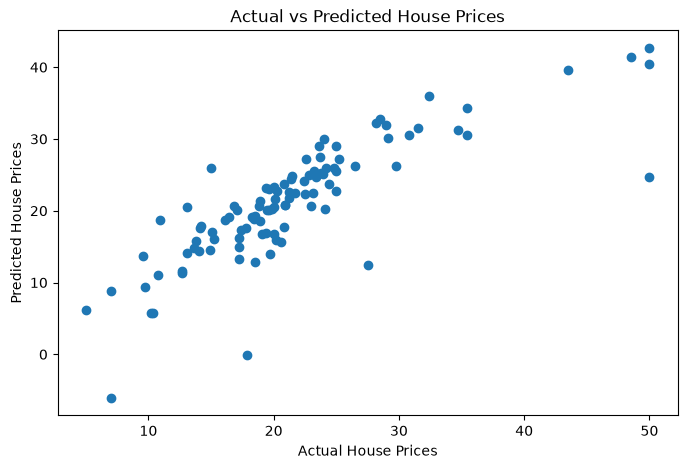

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Prices")

plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [12]:
# Save trained model and preprocessing objects

joblib.dump(
    {
        'model': model,
        'imputer': imputer,
        'scaler': scaler
    },
    'house_price_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [13]:
# Load saved model

saved_data = joblib.load('house_price_model.pkl')

loaded_model = saved_data['model']

# Make prediction

prediction = loaded_model.predict(X_test[:5])

print("Predictions using saved model:")

print(prediction)

Predictions using saved model:
[28.99672362 36.02556534 14.81694405 25.03197915 18.76987992]
